# Felicidad, economía y bienestar en países del mundo

**ICC-321 Inteligencia de Negocios** · Librerías para Visualización de Datos
Prof.: Lisibonny Beato

**Integrantes:**
- Elías De La Cruz Jiménez (1015-5971)
- Enger Nuñez

In [1]:
import glob
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Carga de los datos

El dataset viene en un archivo CSV por año (`WHR_2015.csv` a `WHR_2023.csv`). Se leen todos, se agrega una columna `year` tomada del nombre del archivo y se unen en un solo DataFrame.

- `encoding="utf-8-sig"`: el archivo de 2021 trae al inicio un carácter invisible (BOM) que, sin esta codificación, quedaría pegado al nombre de la columna `country`.
- `re.search(r"(\d{4})", path)`: los CSV no traen el año como columna, solo en el nombre del archivo; esta expresión regular extrae esos 4 dígitos (por ejemplo, `2019` de `WHR_2019.csv`).

In [2]:
frames = []
for path in sorted(glob.glob("WHR_*.csv")):
    df_year = pd.read_csv(path, encoding="utf-8-sig")
    df_year["year"] = int(re.search(r"(\d{4})", path).group(1))
    frames.append(df_year)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(1367, 10)


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


In [3]:
df["year"].value_counts().sort_index()

year
2015    158
2016    157
2017    155
2018    156
2019    156
2020    153
2021    149
2022    146
2023    137
Name: count, dtype: int64

## 2. Filtro al año más reciente

Se identifica el año más reciente disponible con `max()` y se filtra el dataset para quedarse solo con ese año. El resultado es 2023, con 137 países.

In [4]:
ultimo_anio = df["year"].max()
df_reciente = df[df["year"] == ultimo_anio].copy()
print(f"Año más reciente: {ultimo_anio}  |  Países: {len(df_reciente)}")
df_reciente.head()

Año más reciente: 2023  |  Países: 137


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
1230,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535,2023
1231,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525,2023
1232,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187,2023
1233,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158,2023
1234,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394,2023


## 3. Identificación de las columnas

Las columnas del dataset ya tienen nombres claros. Las tres que pide el análisis son:

| Concepto | Columna |
|---|---|
| Puntuación de felicidad (*Ladder score*) | `happiness_score` |
| Riqueza o desarrollo económico | `gdp_per_capita` |
| Salud o bienestar físico | `healthy_life_expectancy` |

En el World Happiness Report, `gdp_per_capita` y `healthy_life_expectancy` no son el PIB en dólares ni la esperanza de vida en años: son la **parte de la puntuación de felicidad que el reporte explica con cada factor**. Por eso sus valores son pequeños (entre 0 y 2.2 aproximadamente), pero mantienen el orden entre países: un valor más alto significa más riqueza o más salud.

In [5]:
print(df_reciente.columns.tolist())

['country', 'region', 'happiness_score', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'year']


## 4. Limpieza de los datos

Antes de graficar se revisan los valores faltantes y los ceros. En este reporte un **0 exacto** en un factor no es un valor real, indica que el dato no estaba disponible:

- Venezuela tiene `gdp_per_capita = 0`, por lo que aparecería como un punto falso pegado al eje.
- Mozambique tiene `healthy_life_expectancy = 0`, por lo que su burbuja no se vería.
- Un país tiene `healthy_life_expectancy` vacío (`NaN`).

Los ceros se convierten en valores faltantes y se eliminan esas filas. Los gráficos usan `df_viz`, el DataFrame limpio.

In [6]:
columnas_analisis = ["happiness_score", "gdp_per_capita", "healthy_life_expectancy"]

print("Valores faltantes:")
print(df_reciente[columnas_analisis].isna().sum())
print("\nPaíses con valor 0 en economía o salud:")
print(df_reciente.loc[(df_reciente["gdp_per_capita"] == 0) | (df_reciente["healthy_life_expectancy"] == 0), ["country", "gdp_per_capita", "healthy_life_expectancy"]])

df_viz = df_reciente.copy()
df_viz[["gdp_per_capita", "healthy_life_expectancy"]] = df_viz[["gdp_per_capita", "healthy_life_expectancy"]].replace(0, pd.NA)
df_viz = df_viz.dropna(subset=columnas_analisis)
df_viz[["gdp_per_capita", "healthy_life_expectancy"]] = df_viz[["gdp_per_capita", "healthy_life_expectancy"]].astype(float)

print(f"\nPaíses antes: {len(df_reciente)}  |  Países después de limpiar: {len(df_viz)}")

Valores faltantes:
happiness_score            0
gdp_per_capita             0
healthy_life_expectancy    1
dtype: int64

Países con valor 0 en economía o salud:
         country  gdp_per_capita  healthy_life_expectancy
1317   Venezuela            0.00                    0.341
1326  Mozambique            0.57                    0.000

Países antes: 137  |  Países después de limpiar: 134


## 5. Scatter plot: riqueza contra felicidad

Eje X: `gdp_per_capita` (economía). Eje Y: `happiness_score` (felicidad). Cada punto es un país.

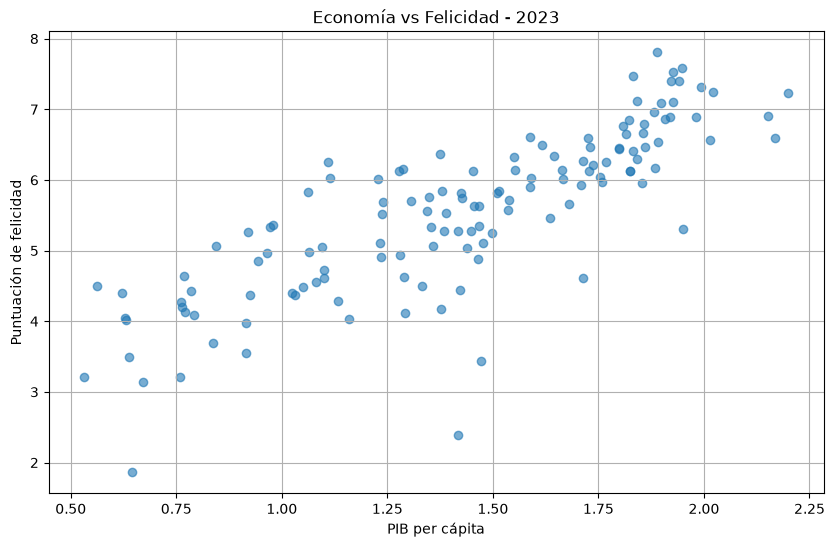

In [7]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_viz["gdp_per_capita"],
    df_viz["happiness_score"],
    alpha=0.6
)

plt.title(f"Economía vs Felicidad - {ultimo_anio}")
plt.xlabel("PIB per cápita")
plt.ylabel("Puntuación de felicidad")

plt.grid(True)
plt.show()

**Qué se ve en este gráfico:** los puntos suben de izquierda a derecha, es decir, los países con mayor PIB per cápita tienden a tener una puntuación de felicidad más alta. La relación es positiva, pero la nube no forma una línea perfecta: para un mismo nivel de riqueza hay países con felicidad bastante distinta, y algunos puntos quedan muy por debajo del resto, como Líbano (felicidad de 2.4 con un PIB intermedio).

**Bondades de la visualización:** el scatter plot es la forma más directa de ver la relación entre dos variables numéricas. Permite ver de un vistazo la dirección de la relación, qué tan fuerte es (qué tan juntos están los puntos) y los países que se alejan del resto. Su límite es que solo muestra dos variables a la vez.

## 6. Gráfico de burbujas: riqueza, felicidad y salud

Se mantienen los mismos ejes del scatter y se agrega una tercera variable: el **tamaño** y el **color** de cada burbuja representan `healthy_life_expectancy` (salud). Mientras más grande y más amarilla la burbuja, mayor es la esperanza de vida sana del país.

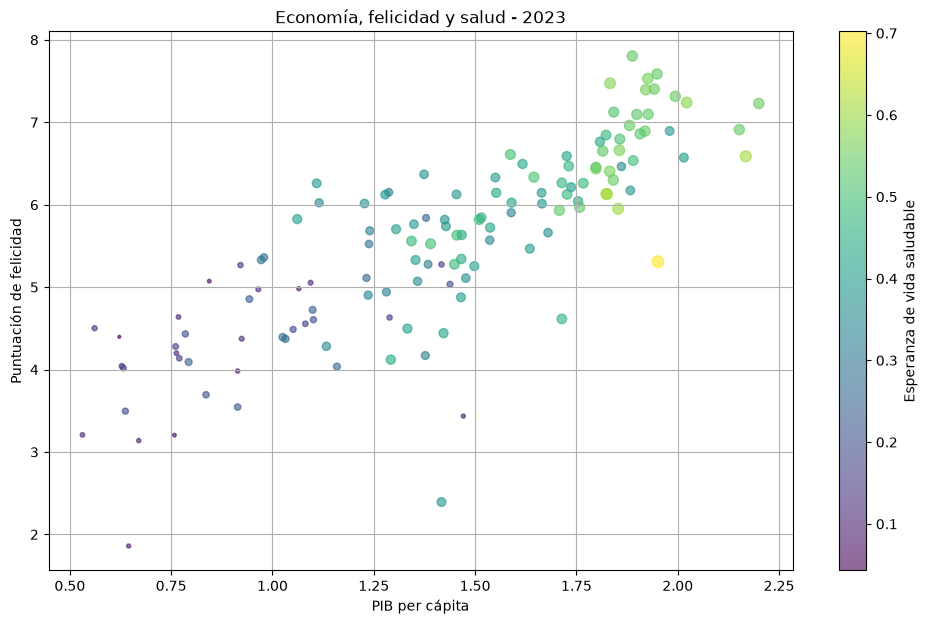

In [8]:
plt.figure(figsize=(12, 7))

plt.scatter(
    df_viz["gdp_per_capita"],
    df_viz["happiness_score"],
    s=df_viz["healthy_life_expectancy"] * 100,
    c=df_viz["healthy_life_expectancy"],
    alpha=0.6,
    cmap="viridis"
)

plt.colorbar(label="Esperanza de vida saludable")

plt.title(f"Economía, felicidad y salud - {ultimo_anio}")
plt.xlabel("PIB per cápita")
plt.ylabel("Puntuación de felicidad")

plt.grid(True)
plt.show()

**Qué se ve en este gráfico:** las burbujas grandes y amarillas (más salud) se concentran arriba a la derecha, y las pequeñas y oscuras abajo a la izquierda. Es decir, los países más ricos tienden a ser también los más sanos y los más felices: riqueza, salud y felicidad van juntas.

**Bondades de la visualización:** el gráfico de burbujas agrega una tercera variable sin perder la lectura del scatter. Usar el color además del tamaño refuerza la lectura de la salud, porque el tamaño por sí solo es difícil de comparar. Su límite es que sirve para ver diferencias grandes, no para leer valores exactos, y las burbujas pueden superponerse.